# 图 7-2　“人才产地”与“人才磁铁”：出生人数—死亡人数散点

复现 Schich et al. (2014) *Science* 345:558–562 图 1C 的样式，对应书稿第七章图 7-2。

**数据与规则**
- 取自论文随文补充材料 S1 的 Freebase 子集，按地点计数后存于 `fig1c_locations.csv`（字段 `loc / births / deaths / z`）；
- 只保留出生与死亡记录都不少于 1 次的地点（双对数轴的要求），共 9,448 个地点；
- 双对数坐标；对角线为出生数＝死亡数；对角线上方（死亡＞出生）为死亡吸引地（红），下方为出生来源地（蓝），恰相等者为灰；
- 两条黑色曲线为显著性边界 |D−B| = z·√(D+B)，取 z = 5。

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

HERE = Path.cwd()
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

# 中文字体（Windows）：直接指定字体族，避免 sans-serif 别名回退导致中文空白
plt.rcParams.update({
    "font.family": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "font.size": 8.5,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.7,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.5,
    "figure.dpi": 110,
})
print("matplotlib", matplotlib.__version__)
print("字体:", plt.rcParams["font.family"])

matplotlib 3.4.3
字体: ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']


In [2]:
# ---------- 1. Freebase 各地点出生数、死亡数 ----------
# 数据来自论文随文补充材料 S1 的 FB 记录（records.pkl，37 MB），
# 按地点计数后的结果已导出为 fig1c_locations.csv（9,448 个出生、死亡均不少于 1 次的地点）。
# 说明：records.pkl 由旧版 pandas 序列化，当前 pandas 无法反序列化，故本 Notebook 直接读汇总表；
#      两者数值一致（见下核对），绘图所需信息（地点、出生数、死亡数）完整。
# 若要从前述原始记录重算，等价代码为：
#     fb = pd.read_pickle(HERE / "records.pkl"); fb = fb[fb["Source"] == "FB"]
#     births, deaths = fb["bkey"].value_counts(), fb["dkey"].value_counts()
#     locs = sorted(set(births.index) & set(deaths.index))

tab = pd.read_csv(HERE / "fig1c_locations.csv")
locs = tab["loc"].tolist()
B_ = tab["births"].to_numpy(float)
D_ = tab["deaths"].to_numpy(float)
lab = tab["loc"]
z = (D_ - B_) / np.sqrt(D_ + B_)

print(f"同时有出生与死亡的地点 {len(locs):,} 个（论文全网 37,062 个）")
print(f"出生合计 {B_.sum():,.0f} 人次；死亡合计 {D_.sum():,.0f} 人次")
print(f"最大出生数 {B_.max():.0f} @ {lab.iloc[B_.argmax()]!r}；最大死亡数 {D_.max():.0f} @ {lab.iloc[D_.argmax()]!r}")
print(f"与存档 z 值最大差异 {np.abs(z - tab['z'].to_numpy()).max():.2e}（应接近 0）")

同时有出生与死亡的地点 9,448 个（论文全网 37,062 个）
出生合计 98,179 人次；死亡合计 107,006 人次
最大出生数 2677 @ 'new york city'；最大死亡数 4146 @ 'los angeles'
与存档 z 值最大差异 5.00e-03（应接近 0）


In [3]:
# ---------- 2. 三类地点与论文标注点核对 ----------
tie, red, blue = D_ == B_, D_ > B_, D_ < B_
print(f"死亡吸引地（D>B）{red.sum():,} 个 | 出生来源地（B>D）{blue.sum():,} 个 | 相等 {tie.sum():,} 个")

idx_of = {k: i for i, k in enumerate(locs)}
paper = ["hollywood", "washington, d.c.", "santa monica", "burbank", "bethesda",
         "russian empire", "ireland", "glasgow", "liverpool", "illinois", "odessa"]


def find(k):
    if k in idx_of:
        return idx_of[k]
    cand = [j for j, s in enumerate(locs) if k in s]
    return cand[0] if cand else None


for k in paper:
    i = find(k)
    print(f"  {k:<18} " + (f"B={B_[i]:.0f}, D={D_[i]:.0f}, z={z[i]:+.1f}" if i is not None else "未找到"))

死亡吸引地（D>B）2,372 个 | 出生来源地（B>D）4,456 个 | 相等 2,620 个
  hollywood          B=49, D=988, z=+29.2
  washington, d.c.   B=354, D=1372, z=+24.5
  santa monica       B=29, D=470, z=+19.7
  burbank            B=11, D=188, z=+12.5
  bethesda           B=3, D=142, z=+11.5
  russian empire     B=86, D=4, z=-8.6
  ireland            B=136, D=21, z=-9.2
  glasgow            B=253, D=102, z=-8.0
  liverpool          B=229, D=89, z=-7.9
  illinois           B=115, D=21, z=-8.1
  odessa             B=116, D=29, z=-7.2


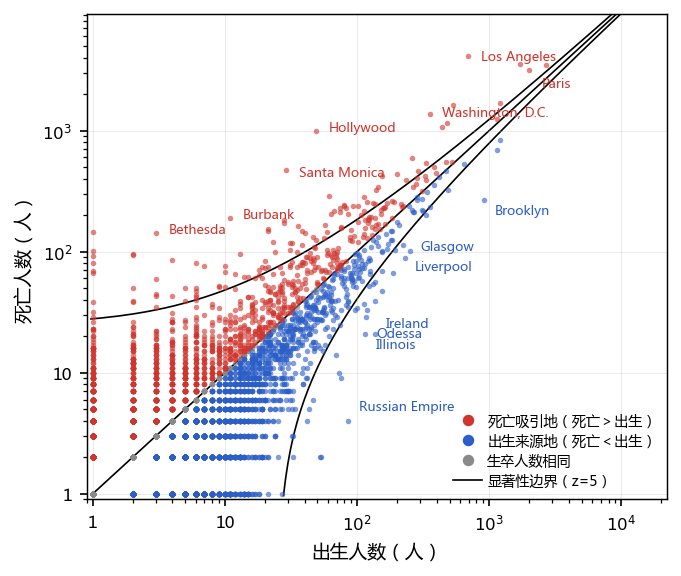

In [4]:
# ---------- 3. 绘图 ----------
C_RED, C_BLUE, C_TIE = "#D0342C", "#2B5EC7", "#8A8A8A"
fig, ax = plt.subplots(figsize=(4.6, 3.9), dpi = 150)

ax.scatter(B_[tie], D_[tie], s=7, c=C_TIE, alpha=0.65, lw=0, rasterized=True, zorder=2)
ax.scatter(B_[blue], D_[blue], s=7, c=C_BLUE, alpha=0.6, lw=0, rasterized=True, zorder=3)
ax.scatter(B_[red], D_[red], s=7, c=C_RED, alpha=0.6, lw=0, rasterized=True, zorder=4)

lims = np.array([1, max(B_.max(), D_.max()) * 2.5])
ax.plot(lims, lims, color="black", lw=0.8, zorder=1)      # 出生 = 死亡

# 显著性边界 |D-B| = 5·sqrt(D+B)
zc = 5.0
S = np.logspace(np.log10(2), np.log10(4 * lims[1]), 400)
bd = (S - zc * np.sqrt(S)) / 2
dd = (S + zc * np.sqrt(S)) / 2
m = bd >= 0.9
ax.plot(bd[m], dd[m], color="black", lw=0.8, zorder=1.5)
ax.plot(dd[m], bd[m], color="black", lw=0.8, zorder=1.5)

# 论文标注的代表性地点
for k, (dx, dy) in [("los angeles", (6, -2)), ("hollywood", (6, 0)), ("washington, d.c.", (6, -1)),
                    ("paris", (10, -11)), ("santa monica", (6, -3)), ("burbank", (6, 0)),
                    ("bethesda", (6, 0))]:
    i = find(k)
    if i is not None:
        ax.annotate(lab.iloc[i].title(), (B_[i], D_[i]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=6.3, color=C_RED, zorder=6)
for k, (dx, dy) in [("brooklyn", (5, -7)), ("russian empire", (5, 5)), ("ireland", (5, 3)),
                    ("glasgow", (5, 0)), ("liverpool", (5, -6)), ("illinois", (5, -7)),
                    ("odessa", (5, -10))]:
    i = find(k)
    if i is not None:
        ax.annotate(lab.iloc[i].title(), (B_[i], D_[i]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=6.3, color=C_BLUE, zorder=6)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(0.9, 2.2e4); ax.set_ylim(0.9, D_.max() * 2.2)
ax.set_xticks([1, 10, 100, 1000, 10000]); ax.set_xticklabels(["1", "10", "$10^2$", "$10^3$", "$10^4$"])
ax.set_yticks([1, 10, 100, 1000]); ax.set_yticklabels(["1", "10", "$10^2$", "$10^3$"])
ax.set_xlabel("出生人数（人）"); ax.set_ylabel("死亡人数（人）")

from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="none", ms=4.5, color=C_RED, label="死亡吸引地（死亡＞出生）"),
           Line2D([], [], marker="o", ls="none", ms=4.5, color=C_BLUE, label="出生来源地（死亡＜出生）"),
           Line2D([], [], marker="o", ls="none", ms=4.5, color=C_TIE, label="生卒人数相同"),
           Line2D([], [], color="black", lw=0.8, label="显著性边界（z=5）")]
ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=6.8,
          handletextpad=0.4, borderaxespad=0.3, labelspacing=0.3)

fig.tight_layout()
plt.show()

In [5]:
# ---------- 4. 保存图片 ----------
out_png = FIG / "fig7_2_scatter_notebook.pdf"
fig.savefig(out_png, bbox_inches="tight", facecolor="white")
print("已保存", out_png.name, f"({out_png.stat().st_size / 1024:.0f} KB)")

tab = pd.DataFrame({"loc": lab, "births": B_.astype(int), "deaths": D_.astype(int),
                    "z": np.round(z, 2)}).sort_values("z", ascending=False)
tab.to_csv(HERE / "fig7-2_locations.csv", index=False, encoding="utf-8-sig")

print("\n最强死亡吸引地（z 最大）:")
print(tab.head(8).to_string(index=False))
print("\n最强出生来源地（z 最小）:")
print(tab.tail(8).iloc[::-1].to_string(index=False))

已保存 fig7_2_scatter_notebook.pdf (62 KB)

最强死亡吸引地（z 最大）:
             loc  births  deaths     z
     los angeles     695    4146 49.60
       hollywood      49     988 29.16
           paris    1720    3540 25.09
washington, d.c.     354    1372 24.50
            rome     527    1611 23.44
    santa monica      29     470 19.74
          moscow     475    1161 16.96
          munich     437    1077 16.45

最强出生来源地（z 最小）:
           loc  births  deaths      z
      brooklyn     910     267 -18.74
  philadelphia    1135     688 -10.47
       ireland     136      21  -9.18
russian empire      86       4  -8.64
       chicago    1213     834  -8.38
      illinois     115      21  -8.06
       glasgow     253     102  -8.01
     liverpool     229      89  -7.85


## 读图要点

- **对角线两侧不是两类地方，而是两种命运**：死亡数多于出生数（红）表示该地被持续指向，是“人才磁铁”；出生数多于死亡数（蓝）表示净输出。
- **规模与磁力是两件事**：横纵轴同时增大只说明地方大（伦敦、巴黎、罗马在对角线附近）；真正偏离对角线的点才说明结构位置——好莱坞死亡数是出生数的十倍以上，而“短命的死亡地点”里混着空难地点、战场与集中营，异常值本身即历史证据。
- **显著性边界是判断门槛**：只有越过 z=5 曲线（即 |D−B| > 5√(D+B)）的点，偏离才超出小样本随机波动的范围。论文正文未给阈值，按约 3.7 万地点的 Bonferroni 校正取整，曲线位置与原图一致。